In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import gzip
import os
import upsetplot

In [ ]:
INDIR= "/net/nwgc/vol1/home/czaka/analysis/mitoscope/smaht/production_analysis/integrated_variant_pipeline/v2_p25"
manifest = pd.read_csv(f'{INDIR}/merge_manifests/p25.merge.txt')
manifest['FilePath'] = manifest['FilePath'].str.split(pat=' ')

def process_item(item):
    file_name = os.path.basename(item)
    x = '-'.join(file_name.split('.')[0].split('-')[2:4])
    return x

manifest['FilePath'] = manifest['FilePath'].apply(lambda x: ','.join([process_item(item) for item in x]))
manifest['num_reps'] = manifest['FilePath'].str.count(',') + 1 

manifest.sort_values('num_reps')

,Donor,Tissue_Code,FilePath,Donor_Tissue,outpath,num_reps
237,SMHT024,3AF,"illumina-mutect2,illumina-mutserve",SMHT024-3AF,/net/nwgc/vol1/home/czaka/analysis/mitoscope/s...,2
286,SMHT029,3AK,"illumina-mutect2,illumina-mutserve",SMHT029-3AK,/net/nwgc/vol1/home/czaka/analysis/mitoscope/s...,2
287,SMHT029,3AL,"illumina-mutect2,illumina-mutserve",SMHT029-3AL,/net/nwgc/vol1/home/czaka/analysis/mitoscope/s...,2
288,SMHT029,3AM,"illumina-mutect2,illumina-mutserve",SMHT029-3AM,/net/nwgc/vol1/home/czaka/analysis/mitoscope/s...,2
289,SMHT029,3AN,"illumina-mutect2,illumina-mutserve",SMHT029-3AN,/net/nwgc/vol1/home/czaka/analysis/mitoscope/s...,2
...,...,...,...,...,...,...
45,SMHT005,3C,"illumina-mutect2,illumina-mutserve,pacbio-mito...",SMHT005-3C,/net/nwgc/vol1/home/czaka/analysis/mitoscope/s...,6
392,SMHT043,3O,"illumina-mutect2,illumina-mutserve,pacbio-mito...",SMHT043-3O,/net/nwgc/vol1/home/czaka/analysis/mitoscope/s...,6
2,SMHT001,3AD,"illumina-mutect2,illumina-mutserve,pacbio-mito...",SMHT001-3AD,/net/nwgc/vol1/home/czaka/analysis/mitoscope/s...,6
394,SMHT043,3U,"illumina-mutect2,illumina-mutserve,pacbio-mito...",SMHT043-3U,/net/nwgc/vol1/home/czaka/analysis/mitoscope/s...,6


In [24]:
manifest_expanded = manifest.assign(reps=manifest['FilePath'].str.split(',')).explode('reps')
manifest_expanded[['Tech', 'Tool']] = manifest_expanded['reps'].str.split('-', expand=True)
manifest_expanded = manifest_expanded[['Donor_Tissue', 'Donor', 'Tissue_Code', 'Tech', 'Tool', 'reps']].drop_duplicates()

availability = manifest_expanded.groupby(['Donor_Tissue', 'Donor', 'Tissue_Code']).agg(
        avail_techs=("Tech", lambda x: '+'.join(sorted(x.astype(str).unique()))),
        n_avail_techs=("Tech", 'nunique'),
        avail_reps=("reps", lambda x: '+'.join(sorted(x.astype(str).unique()))),
        n_avail_reps=("reps", 'nunique')).reset_index()

availability.sort_values('n_avail_reps')

,Donor_Tissue,Donor,Tissue_Code,avail_techs,n_avail_techs,avail_reps,n_avail_reps
237,SMHT024-3AF,SMHT024,3AF,illumina,1,illumina-mutect2+illumina-mutserve,2
286,SMHT029-3AK,SMHT029,3AK,illumina,1,illumina-mutect2+illumina-mutserve,2
287,SMHT029-3AL,SMHT029,3AL,illumina,1,illumina-mutect2+illumina-mutserve,2
288,SMHT029-3AM,SMHT029,3AM,illumina,1,illumina-mutect2+illumina-mutserve,2
289,SMHT029-3AN,SMHT029,3AN,illumina,1,illumina-mutect2+illumina-mutserve,2
...,...,...,...,...,...,...,...
45,SMHT005-3C,SMHT005,3C,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6
392,SMHT043-3O,SMHT043,3O,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6
2,SMHT001-3AD,SMHT001,3AD,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6
394,SMHT043-3U,SMHT043,3U,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6


In [25]:
tissue_availability = manifest.groupby(['Donor']).agg(
        avail_tissues=("Tissue_Code", lambda x: '+'.join(sorted(x.astype(str).unique()))),
        n_avail_tissues=("Tissue_Code", 'nunique')
)

availability = availability.merge(tissue_availability, on=['Donor'], how='left')
availability = availability.drop(columns=['Donor', 'Tissue_Code'])
availability

,Donor_Tissue,avail_techs,n_avail_techs,avail_reps,n_avail_reps,avail_tissues,n_avail_tissues
0,SMHT001-3A,illumina+pacbio,2,illumina-mutect2+illumina-mutserve+pacbio-himi...,4,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3B+3C+3...,20
1,SMHT001-3AC,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3B+3C+3...,20
2,SMHT001-3AD,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3B+3C+3...,20
3,SMHT001-3AF,illumina+ont,2,illumina-mutect2+illumina-mutserve+ont-himito+...,4,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3B+3C+3...,20
4,SMHT001-3AH,illumina+ont,2,illumina-mutect2+illumina-mutserve+ont-himito+...,4,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3B+3C+3...,20
...,...,...,...,...,...,...,...
390,SMHT043-3I,illumina,1,illumina-mutect2+illumina-mutserve,2,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3B+3C+3E+3G...,18
391,SMHT043-3K,illumina,1,illumina-mutect2+illumina-mutserve,2,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3B+3C+3E+3G...,18
392,SMHT043-3O,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3B+3C+3E+3G...,18
393,SMHT043-3Q,illumina+ont,2,illumina-mutect2+illumina-mutserve+ont-himito+...,4,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3B+3C+3E+3G...,18


/net/wei/vol1/home/czaka/miniforge3/lib/python3.10/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/net/wei/vol1/home/czaka/miniforge3/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["l

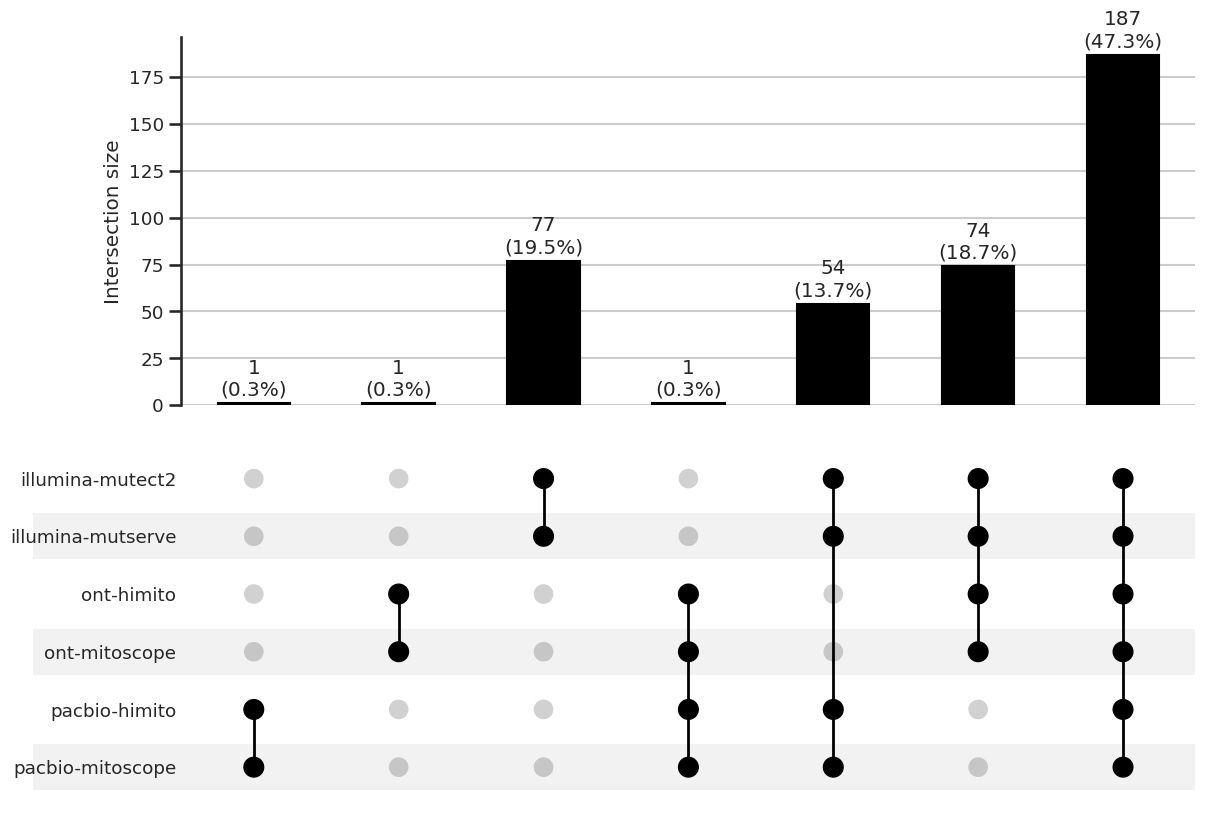

In [ ]:
upset_df = upsetplot.from_memberships(manifest.FilePath.str.split(","), data=manifest)
upset_df

sns.set_theme(style="ticks", context="talk", font_scale=0.8)

fig = plt.figure(figsize=(15,10))
t = upsetplot.UpSet(upset_df, element_size=None, sort_categories_by="-input", sort_by="degree", show_percentages=True, show_counts=True, totals_plot_elements=0)
t.plot(fig)
plt.suptitle("", size=14)
plt.show()

In [27]:
blacklist=[3107]

def read_vcf(input_file):
    with gzip.open(input_file, 'rt') as fr:
        for line in fr:
            if line.startswith('#CHROM'):
                header = line.strip().lstrip('#').split('\t')
                break

    df = pd.read_csv(input_file, comment='#', sep='\t', compression='gzip', names=header)
    return df

comb_df = pd.DataFrame()

for sample in manifest['Donor_Tissue']:
    if os.path.isfile(f"{INDIR}/output/merged/{sample}.vcf.gz"):
        df = read_vcf(f"{INDIR}/output/merged/{sample}.vcf.gz")
        df['ID'] = df[['CHROM', 'POS', 'REF', 'ALT']].astype(str).agg('-'.join, axis=1)

        sample_col = [col for col in df if col.startswith('SMHT')]
        df = pd.melt(
            df[["POS", "ID"] + sample_col],
            id_vars=['POS', 'ID'],
            var_name='Sample',
            value_name='Value'
        )
        comb_df = pd.concat([comb_df, df])
    else:
        print(f'{sample} VCF is missing')
    
comb_df[['Donor', 'Tissue', 'Tech','Tool']] = comb_df['Sample'].str.split('-', expand=True)
comb_df = comb_df[comb_df['Value'] != '.:.']
comb_df[['GT', 'AF']] = comb_df['Value'].str.split(':', expand=True)
comb_df['AF'] = comb_df['AF'].astype(float)
comb_df['Donor_Tissue'] = comb_df['Donor'] + "-" + comb_df['Tissue']
comb_df['Tech_Tool'] = comb_df['Tech'] + "_" + comb_df['Tool']

comb_df = comb_df[~comb_df['POS'].isin(blacklist)]
comb_df = comb_df.drop(columns=['POS', 'Sample', 'Value', 'GT'])
comb_df


,ID,Donor,Tissue,Tech,Tool,AF,Donor_Tissue,Tech_Tool
1,chrM-42-T-TC,SMHT001,3A,illumina,mutect2,0.999000,SMHT001-3A,illumina_mutect2
2,chrM-73-A-G,SMHT001,3A,illumina,mutect2,1.000000,SMHT001-3A,illumina_mutect2
3,chrM-146-T-C,SMHT001,3A,illumina,mutect2,1.000000,SMHT001-3A,illumina_mutect2
5,chrM-214-A-G,SMHT001,3A,illumina,mutect2,0.004415,SMHT001-3A,illumina_mutect2
6,chrM-263-A-G,SMHT001,3A,illumina,mutect2,1.000000,SMHT001-3A,illumina_mutect2
...,...,...,...,...,...,...,...,...
925,chrM-14798-T-C,SMHT043,3U,ont,himito,0.997395,SMHT043-3U,ont_himito
930,chrM-15326-A-G,SMHT043,3U,ont,himito,0.997836,SMHT043-3U,ont_himito
931,chrM-15452-C-A,SMHT043,3U,ont,himito,0.995688,SMHT043-3U,ont_himito
933,chrM-16069-C-T,SMHT043,3U,ont,himito,1.000000,SMHT043-3U,ont_himito


In [28]:
tech_means = (
    comb_df
    .groupby(["Donor", "Tissue", "Donor_Tissue", "ID", "Tech"])
    .agg(mean_tech_AF=("AF", "mean"))
    .reset_index()
).pivot(index=['Donor_Tissue', 'ID'], columns='Tech', values='mean_tech_AF').reset_index()

tech_means = tech_means.fillna('.')

tech_means

Tech,Donor_Tissue,ID,illumina,ont,pacbio
0,SMHT001-3A,chrM-10550-A-G,0.9995,.,1.0
1,SMHT001-3A,chrM-11299-T-C,1.0,.,1.0
2,SMHT001-3A,chrM-11467-A-G,1.0,.,0.99689
3,SMHT001-3A,chrM-11719-G-A,1.0,.,1.0
4,SMHT001-3A,chrM-12308-A-G,0.999,.,0.996145
...,...,...,...,...,...
30026,SMHT043-3U,chrM-8860-A-G,1.0,0.999383,1.0
30027,SMHT043-3U,chrM-9005-T-C,.,.,0.006806
30028,SMHT043-3U,chrM-9727-C-A,.,.,0.004334
30029,SMHT043-3U,chrM-9794-AT-A,.,.,0.10987


In [29]:
collapsed_df = (
    comb_df
    .groupby(["ID", "Donor", "Tissue", "Donor_Tissue"])
    .agg(
        n_tools=("Tool", "nunique"),
        tools=("Tool", lambda x: '+'.join(sorted(x.astype(str).unique()))),
        n_techs=("Tech", "nunique"),
        techs=("Tech", lambda x: '+'.join(sorted(x.astype(str).unique()))),
        n_reps=("Tech_Tool", "nunique"),
        mean_af=("AF", "mean"),
        std_af=("AF", "std"),
    ).reset_index()
)

collapsed_df = collapsed_df.merge(tech_means, on=['Donor_Tissue', 'ID'], how='left')
collapsed_df = collapsed_df.merge(availability, on='Donor_Tissue', how='left')
collapsed_df

,ID,Donor,Tissue,Donor_Tissue,n_tools,tools,n_techs,techs,n_reps,mean_af,std_af,illumina,ont,pacbio,avail_techs,n_avail_techs,avail_reps,n_avail_reps,avail_tissues,n_avail_tissues
0,chrM-1000-T-C,SMHT020,3AD,SMHT020-3AD,1,mutserve,1,illumina,1,0.002000,NaN,0.002,.,.,illumina,1,illumina-mutect2+illumina-mutserve,2,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3C+3E+3...,19
1,chrM-10007-T-G,SMHT022,3K,SMHT022-3K,2,mutect2+mutserve,1,illumina,2,0.005491,0.000719,0.005491,.,.,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6,3A+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3C+3E+3G+3I...,18
2,chrM-10010-T-C,SMHT007,3U,SMHT007-3U,2,himito+mitoscope,1,pacbio,2,0.013041,0.002321,.,.,0.013041,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6,3A+3AD+3AF+3AH+3AK+3AL+3AM+3AO+3C+3E+3G+3I+3O+...,16
3,chrM-10010-T-C,SMHT024,3C,SMHT024-3C,2,himito+mitoscope,1,pacbio,2,0.004402,0.000950,.,.,0.004402,illumina+pacbio,2,illumina-mutect2+illumina-mutserve+pacbio-himi...,4,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3B+3C+3...,19
4,chrM-10010-T-C,SMHT039,3U,SMHT039-3U,1,mutserve,1,illumina,1,0.003000,NaN,0.003,.,.,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6,3A+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3E+3G+3I+3K...,17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30026,chrM-9987-T-C,SMHT027,3K,SMHT027-3K,1,mutserve,1,illumina,1,0.004000,NaN,0.004,.,.,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6,3A+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3C+3E+3G+3I...,17
30027,chrM-9989-T-C,SMHT035,3I,SMHT035-3I,1,mutserve,1,illumina,1,0.003000,NaN,0.003,.,.,illumina,1,illumina-mutect2+illumina-mutserve,2,3A+3AD+3AF+3C+3E+3G+3I+3K+3O+3Q+3S+3Y,12
30028,chrM-999-C-T,SMHT012,3Q,SMHT012-3Q,1,himito,1,ont,1,0.003902,NaN,.,0.003902,.,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6,3A+3AC+3AD+3AF+3AH+3C+3E+3I+3K+3O+3Q+3S+3U,13
30029,chrM-9998-T-C,SMHT024,3AF,SMHT024-3AF,2,mutect2+mutserve,1,illumina,2,0.004286,0.001010,0.004286,.,.,illumina,1,illumina-mutect2+illumina-mutserve,2,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3B+3C+3...,19


In [30]:
collapsed_df['tissue_reps'] = (
    collapsed_df
    .groupby(['ID', 'Donor'])['Tissue']
    .transform('count')
)

collapsed_df['tissue_rep_names'] = (
    collapsed_df
    .groupby(['ID', 'Donor'])['Tissue']
    .transform(lambda x: '+'.join(sorted(x.astype(str).unique())))
)

collapsed_df

,ID,Donor,Tissue,Donor_Tissue,n_tools,tools,n_techs,techs,n_reps,mean_af,...,ont,pacbio,avail_techs,n_avail_techs,avail_reps,n_avail_reps,avail_tissues,n_avail_tissues,tissue_reps,tissue_rep_names
0,chrM-1000-T-C,SMHT020,3AD,SMHT020-3AD,1,mutserve,1,illumina,1,0.002000,...,.,.,illumina,1,illumina-mutect2+illumina-mutserve,2,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3C+3E+3...,19,1,3AD
1,chrM-10007-T-G,SMHT022,3K,SMHT022-3K,2,mutect2+mutserve,1,illumina,2,0.005491,...,.,.,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6,3A+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3C+3E+3G+3I...,18,1,3K
2,chrM-10010-T-C,SMHT007,3U,SMHT007-3U,2,himito+mitoscope,1,pacbio,2,0.013041,...,.,0.013041,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6,3A+3AD+3AF+3AH+3AK+3AL+3AM+3AO+3C+3E+3G+3I+3O+...,16,1,3U
3,chrM-10010-T-C,SMHT024,3C,SMHT024-3C,2,himito+mitoscope,1,pacbio,2,0.004402,...,.,0.004402,illumina+pacbio,2,illumina-mutect2+illumina-mutserve+pacbio-himi...,4,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3B+3C+3...,19,1,3C
4,chrM-10010-T-C,SMHT039,3U,SMHT039-3U,1,mutserve,1,illumina,1,0.003000,...,.,.,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6,3A+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3E+3G+3I+3K...,17,1,3U
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30026,chrM-9987-T-C,SMHT027,3K,SMHT027-3K,1,mutserve,1,illumina,1,0.004000,...,.,.,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6,3A+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3C+3E+3G+3I...,17,1,3K
30027,chrM-9989-T-C,SMHT035,3I,SMHT035-3I,1,mutserve,1,illumina,1,0.003000,...,.,.,illumina,1,illumina-mutect2+illumina-mutserve,2,3A+3AD+3AF+3C+3E+3G+3I+3K+3O+3Q+3S+3Y,12,1,3I
30028,chrM-999-C-T,SMHT012,3Q,SMHT012-3Q,1,himito,1,ont,1,0.003902,...,0.003902,.,illumina+ont+pacbio,3,illumina-mutect2+illumina-mutserve+ont-himito+...,6,3A+3AC+3AD+3AF+3AH+3C+3E+3I+3K+3O+3Q+3S+3U,13,1,3Q
30029,chrM-9998-T-C,SMHT024,3AF,SMHT024-3AF,2,mutect2+mutserve,1,illumina,2,0.004286,...,.,.,illumina,1,illumina-mutect2+illumina-mutserve,2,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3B+3C+3...,19,1,3AF


In [ ]:
collapsed_df['CrossTech'] = np.where(collapsed_df['n_techs'] > 1, True, False)
collapsed_df['CrossTool'] = np.where(collapsed_df['n_tools'] > 1, True, False)
collapsed_df['CrossTissue'] = np.where(collapsed_df['tissue_reps'] > 1, True, False)

collapsed_df['Category_Count'] = collapsed_df[['CrossTech','CrossTool', 'CrossTissue']].sum(axis=1)

conditions = [
    (collapsed_df['Category_Count'] == 0),
    (~collapsed_df['CrossTech']) & (collapsed_df['Category_Count'] == 1),
    (collapsed_df['CrossTech']) | (collapsed_df['Category_Count'] > 1)
]

values = ['LikelyArtifact', 'LowConf', 'HighConf']
collapsed_df['tier'] = np.select(conditions, values, default='-')

collapsed_df[['CHROM', 'POS', 'REF', 'ALT']] = collapsed_df['ID'].str.split('-', expand=True)
collapsed_df['indel'] = collapsed_df.apply(lambda row: 'indel' if (len(row['REF']) > 1 or len(row['ALT']) > 1) else 'snv', axis=1)
collapsed_df['heteroplasmy_category'] = np.where(collapsed_df['mean_af'] >= 0.95, 'homo', 'hetero')
collapsed_df['variant_origin'] = np.where(collapsed_df['tissue_reps'] == collapsed_df['n_avail_tissues'], 'germline', 'somatic')
collapsed_df

,ID,Donor,Tissue,Donor_Tissue,n_tools,tools,n_techs,techs,n_reps,mean_af,...,n_avail_reps,avail_tissues,n_avail_tissues,tissue_reps,tissue_rep_names,CrossTech,CrossTool,CrossTissue,Category_Count,tier
0,chrM-1000-T-C,SMHT020,3AD,SMHT020-3AD,1,mutserve,1,illumina,1,0.002000,...,2,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3C+3E+3...,19,1,3AD,False,False,False,0,LikelyArtifact
1,chrM-10007-T-G,SMHT022,3K,SMHT022-3K,2,mutect2+mutserve,1,illumina,2,0.005491,...,6,3A+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3C+3E+3G+3I...,18,1,3K,False,True,False,1,LowConf
2,chrM-10010-T-C,SMHT007,3U,SMHT007-3U,2,himito+mitoscope,1,pacbio,2,0.013041,...,6,3A+3AD+3AF+3AH+3AK+3AL+3AM+3AO+3C+3E+3G+3I+3O+...,16,1,3U,False,True,False,1,LowConf
3,chrM-10010-T-C,SMHT024,3C,SMHT024-3C,2,himito+mitoscope,1,pacbio,2,0.004402,...,4,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3B+3C+3...,19,1,3C,False,True,False,1,LowConf
4,chrM-10010-T-C,SMHT039,3U,SMHT039-3U,1,mutserve,1,illumina,1,0.003000,...,6,3A+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3E+3G+3I+3K...,17,1,3U,False,False,False,0,LikelyArtifact
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30026,chrM-9987-T-C,SMHT027,3K,SMHT027-3K,1,mutserve,1,illumina,1,0.004000,...,6,3A+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3C+3E+3G+3I...,17,1,3K,False,False,False,0,LikelyArtifact
30027,chrM-9989-T-C,SMHT035,3I,SMHT035-3I,1,mutserve,1,illumina,1,0.003000,...,2,3A+3AD+3AF+3C+3E+3G+3I+3K+3O+3Q+3S+3Y,12,1,3I,False,False,False,0,LikelyArtifact
30028,chrM-999-C-T,SMHT012,3Q,SMHT012-3Q,1,himito,1,ont,1,0.003902,...,6,3A+3AC+3AD+3AF+3AH+3C+3E+3I+3K+3O+3Q+3S+3U,13,1,3Q,False,False,False,0,LikelyArtifact
30029,chrM-9998-T-C,SMHT024,3AF,SMHT024-3AF,2,mutect2+mutserve,1,illumina,2,0.004286,...,2,3A+3AC+3AD+3AF+3AH+3AK+3AL+3AM+3AN+3AO+3B+3C+3...,19,1,3AF,False,True,False,1,LowConf


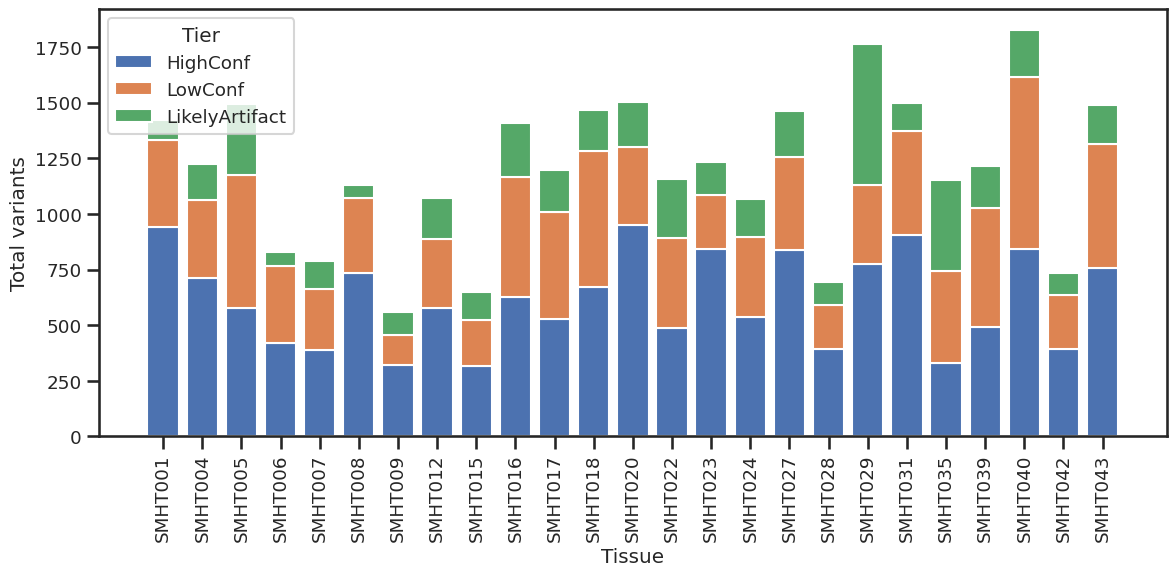

In [33]:
tier_counts = collapsed_df.groupby(['Donor','tier'])['ID'].count().unstack(fill_value=0)
tier_counts

sns.set_theme(style="ticks", context="talk", font_scale=0.8)
fig, ax = plt.subplots(figsize=(12,6))
bottom = None
order = ['HighConf', 'LowConf', 'LikelyArtifact']

#tier_counts = tier_counts.loc[tier_counts.sum(axis=1).sort_values(ascending=False).index]

for tier in order:
    ax.bar(tier_counts.index, tier_counts[tier], bottom=bottom, label=tier)
    if bottom is None:
        bottom = tier_counts[tier].copy()
    else:
        bottom += tier_counts[tier]

ax.set_ylabel('Total variants')
ax.set_xlabel('Tissue')
ax.legend(title='Tier')
plt.xticks(rotation=90)
#plt.ylim(0,90)
plt.tight_layout()


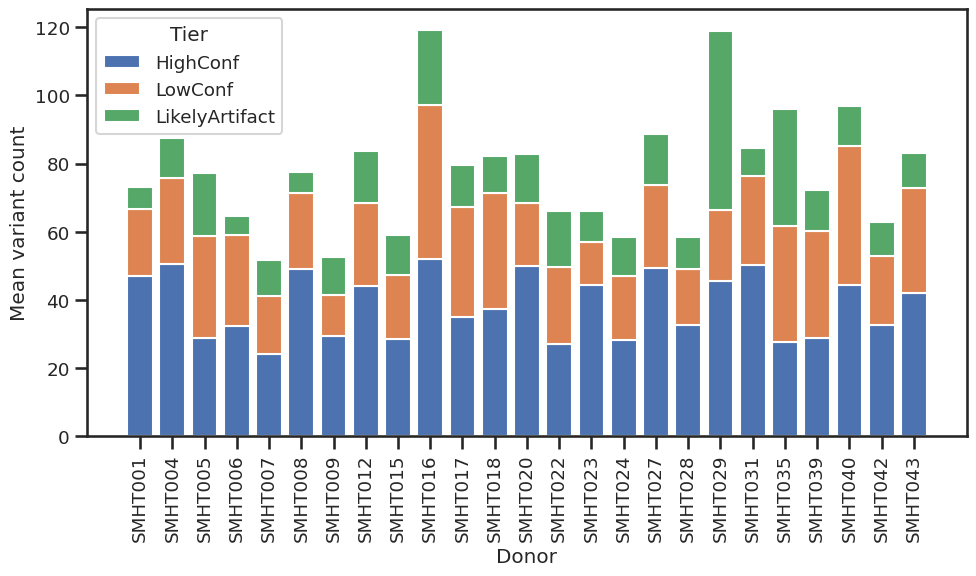

In [34]:
# count IDs per donor/tissue/tier
counts = (
    collapsed_df
    .groupby(['Donor', 'Tissue', 'tier'])['ID']
    .count()
    .reset_index(name='count')
)

# average across tissues within each donor
tier_counts2 = (
    counts
    .groupby(['Donor', 'tier'])['count']
    .mean()
    .unstack(fill_value=0)
    .reset_index()
)

tier_counts2

sns.set_theme(style="ticks", context="talk", font_scale=0.8)

fig, ax = plt.subplots(figsize=(10, 6))

bottom = np.zeros(len(tier_counts2))
order = ['HighConf', 'LowConf', 'LikelyArtifact']

for tier in order:
    values = tier_counts2[tier]
    ax.bar(
        tier_counts2['Donor'],
        values,
        bottom=bottom,
        label=tier
    )
    bottom += values

ax.set_ylabel('Mean variant count')
ax.set_xlabel('Donor')
ax.legend(title='Tier')
plt.xticks(rotation=90, ha='center')
plt.tight_layout()

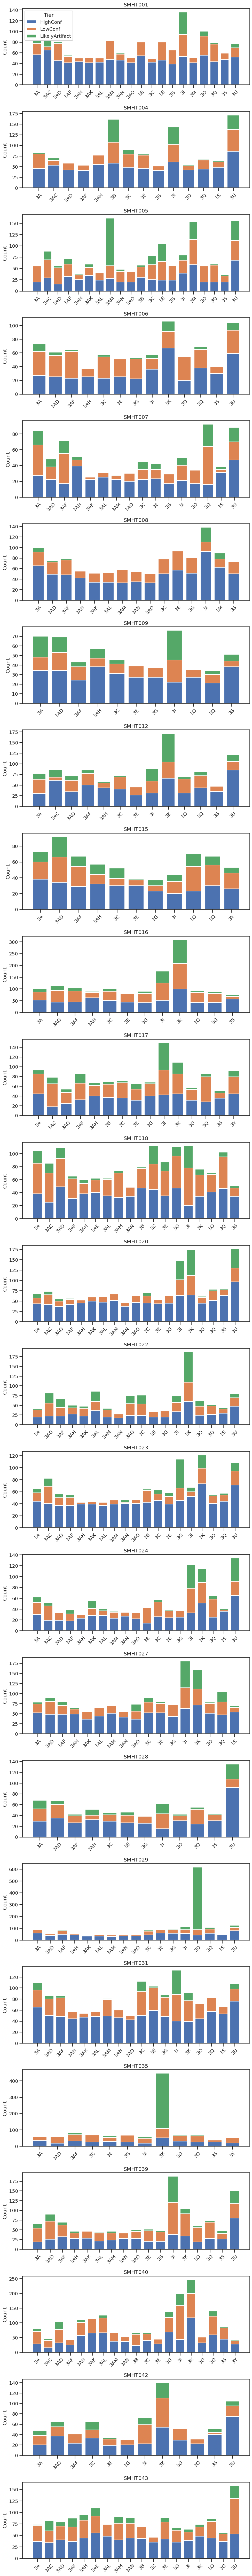

In [35]:
tier_counts = collapsed_df.groupby(['Donor', 'Tissue', 'tier'])['ID'].count().unstack(fill_value=0).reset_index()

sns.set_theme(style="ticks", context="talk", font_scale=0.8)

order = ['HighConf', 'LowConf', 'LikelyArtifact']
donors = tier_counts['Donor'].unique()

fig, axes = plt.subplots(len(donors), 1, figsize=(10, 4 * len(donors)), sharex=False)

for ax, donor in zip(axes, donors):

    df = tier_counts[tier_counts['Donor'] == donor]
    bottom = None
    x = range(len(df))

    for tier in order:
        vals = df[tier]
        ax.bar(x, vals, bottom=bottom, label=tier)

        if bottom is None:
            bottom = vals.copy()
        else:
            bottom += vals

    ax.set_title(donor)
    ax.set_ylabel("Count")
    ax.set_xticks(x)
    ax.set_xticklabels(df["Tissue"], rotation=45)

axes[0].legend(title="Tier")
plt.tight_layout()
plt.show()

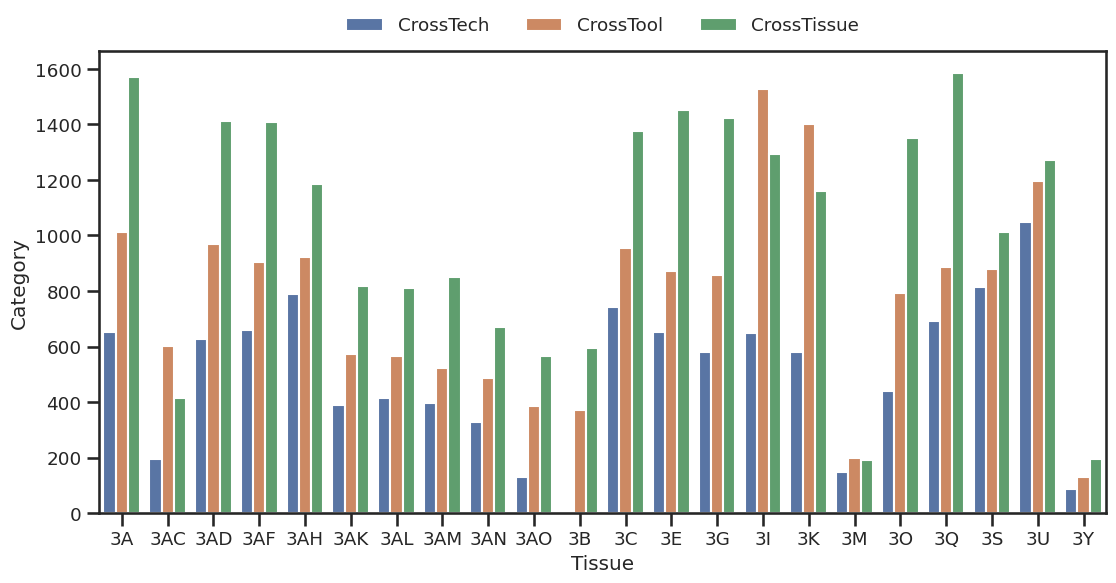

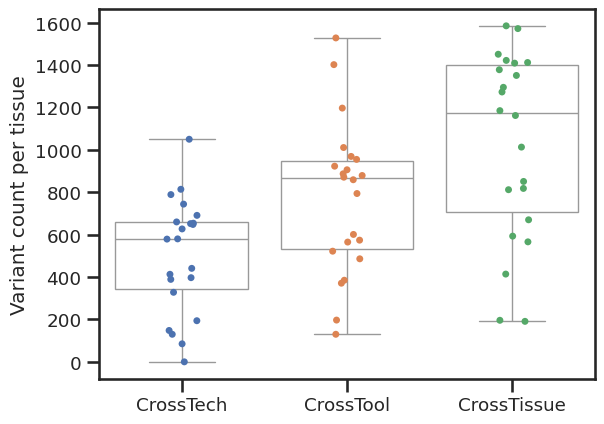

In [37]:
cat_counts = collapsed_df.groupby(['Tissue'])[['CrossTech', 'CrossTool', 'CrossTissue']].sum().stack().reset_index()
cat_counts.columns = ['Tissue', 'Category', 'Value']
cat_counts

sns.set_theme(style="ticks", context="talk", font_scale=0.8)
fig = plt.figure(figsize=(13,6))
ax = sns.barplot(data=cat_counts, x='Tissue', y='Value', hue='Category')
sns. move_legend(ax, "lower center",bbox_to_anchor=(.5, 1), ncol=4, title=None, frameon=False) 
plt.xlabel('Tissue')
plt.ylabel('Category')
plt.show()

sns.set_theme(style="ticks", context="talk", font_scale=0.8)
sns.stripplot(cat_counts, x='Category', y='Value', hue='Category')
sns.boxplot(cat_counts, x='Category', y='Value', showfliers=False, color='white')
plt.xlabel('')
plt.ylabel('Variant count per tissue')
plt.show()



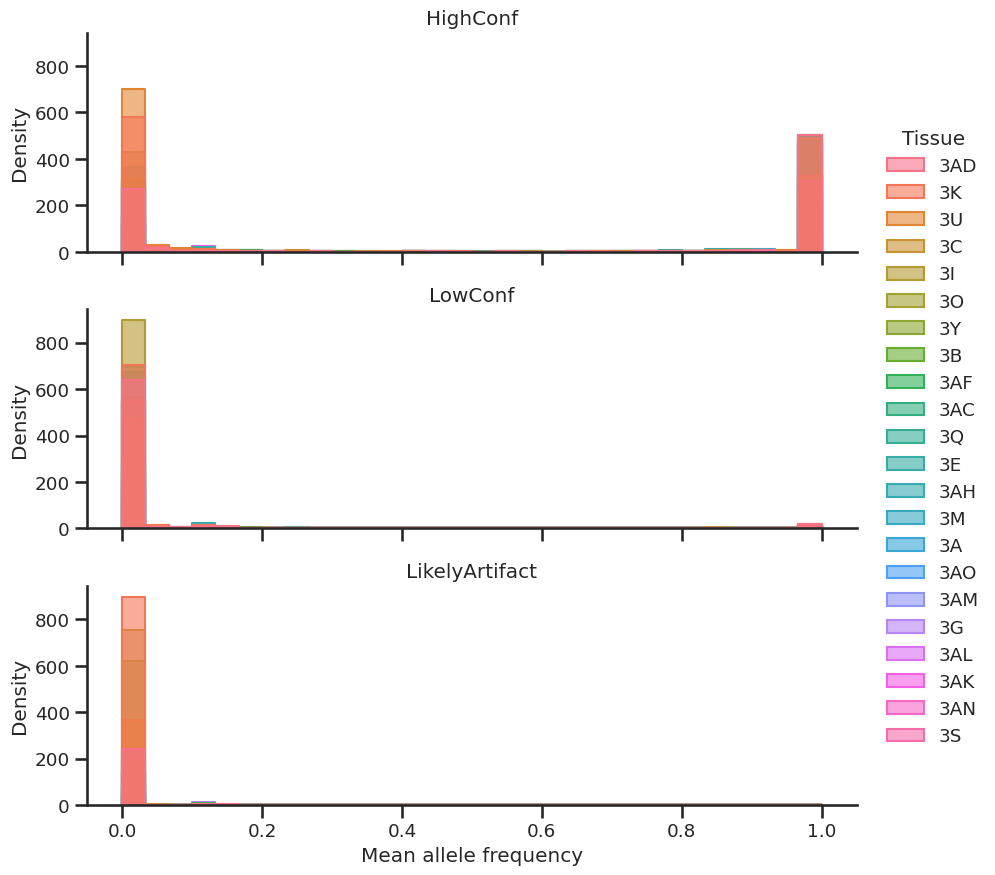

In [38]:
sns.set_theme(style="ticks", context="talk", font_scale=0.8)

g = sns.displot(
    data=collapsed_df,
    row_order=['HighConf', 'LowConf', 'LikelyArtifact'],
    x='mean_af',
    hue='Tissue',
    row='tier',
    kind='hist',
    bins=30,
    element='step',
    stat='count',
  #  common_norm=True,
    alpha=0.6,
    height=3,
    aspect=3
)

g.set_axis_labels("Mean allele frequency", "Density")
g.set_titles(row_template="{row_name}")
plt.show()

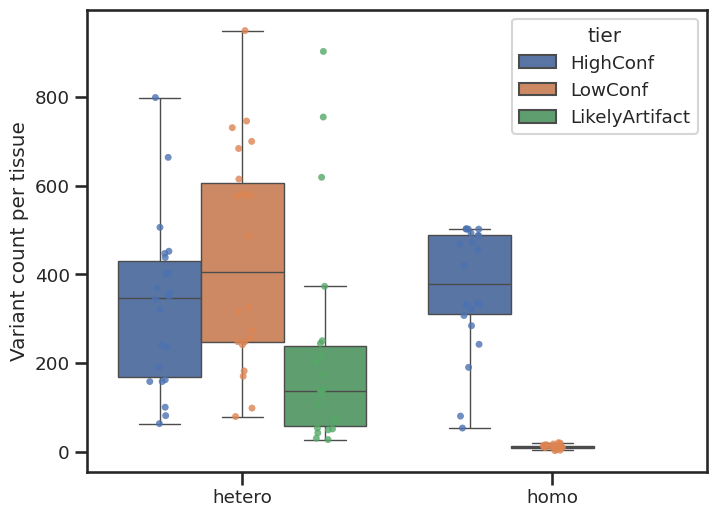

In [39]:
het_counts = collapsed_df.groupby(['Tissue', 'tier', 'heteroplasmy_category'])['ID'].count().unstack()
t = het_counts.stack().rename('variant_count').reset_index()

sns.set_theme(style="ticks", context="talk", font_scale=0.8)
plt.figure(figsize=(8,6))

sns.boxplot(
    data=t,
    hue='tier',
    y='variant_count',
    x='heteroplasmy_category',
    hue_order=['HighConf', 'LowConf', 'LikelyArtifact'],
    showfliers=False,
    dodge=True
)

sns.stripplot(
    data=t,
    hue='tier',
    y='variant_count',
    x='heteroplasmy_category',
    hue_order=['HighConf', 'LowConf', 'LikelyArtifact'],
    dodge=True,
    alpha=0.8,
    jitter=True,
    legend=False
)

plt.xlabel('')
plt.ylabel('Variant count per tissue')

plt.show()

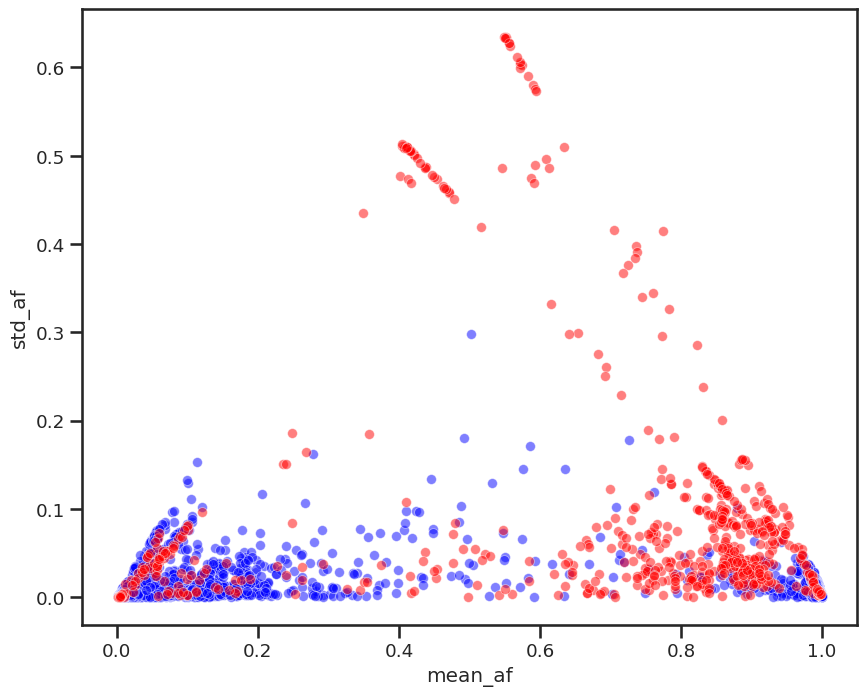

In [40]:
prob_ids = [
    'chrM-310-T-C', 'chrM-310-T-TC', 'chrM-309-C-CCT', 'chrM-302-A-AC', 'chrM-16189-T-C'
]

mask = collapsed_df['ID'].isin(prob_ids)

plt.figure(figsize=(10,8))

# background points
sns.scatterplot(
    data=collapsed_df[~mask],
    x='mean_af',
    y='std_af',
    color='blue',
    alpha=0.5,
    s=50
)

# highlighted points
sns.scatterplot(
    data=collapsed_df[mask],
    x='mean_af',
    y='std_af',
    color='red',
    alpha=0.5,
    s=50
)

plt.show()



,Donor,Tissue,ID,Tech,mean_af,std_af
2883,SMHT004,3AD,chrM-16189-T-C,ont,0.891886,0.143082
2998,SMHT004,3AF,chrM-16189-T-C,ont,0.906701,0.130630
3117,SMHT004,3AH,chrM-16189-T-C,ont,0.907089,0.127309
3446,SMHT004,3C,chrM-16189-T-C,ont,0.905209,0.132075
3613,SMHT004,3E,chrM-16189-T-C,ont,0.905083,0.130231
3747,SMHT004,3G,chrM-16189-T-C,ont,0.904429,0.131353
3896,SMHT004,3I,chrM-16189-T-C,ont,0.917057,0.113113
4073,SMHT004,3O,chrM-16189-T-C,ont,0.893946,0.144354
4190,SMHT004,3Q,chrM-16189-T-C,ont,0.922990,0.103875
4339,SMHT004,3S,chrM-16189-T-C,ont,0.895811,0.143471


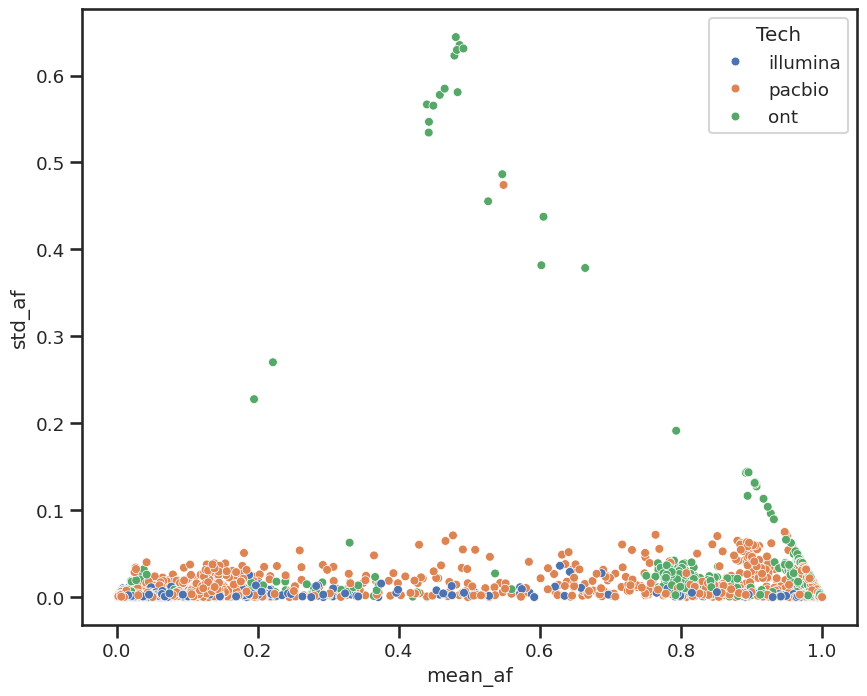

In [41]:
w = comb_df.groupby(['Donor', 'Tissue', 'ID', 'Tech']).agg(
    mean_af=("AF", "mean"),
    std_af=("AF", "std")
).reset_index()

plt.figure(figsize=(10,8))
sns.scatterplot(w, x='mean_af', y='std_af', hue='Tech', s=40)
w[w['std_af'] > 0.1]

#w

/tmp/ipykernel_2193816/2816795907.py:9: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  corr = df_wide.drop(columns=['ID','Donor_Tissue']).corr()
/tmp/ipykernel_2193816/2816795907.py:13: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  plot_df = df_wide.drop(columns=['ID', 'Donor_Tissue'])


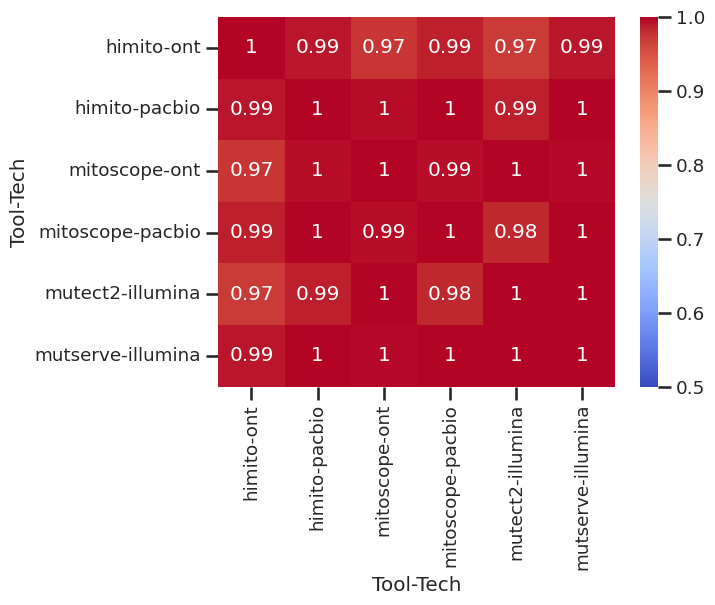

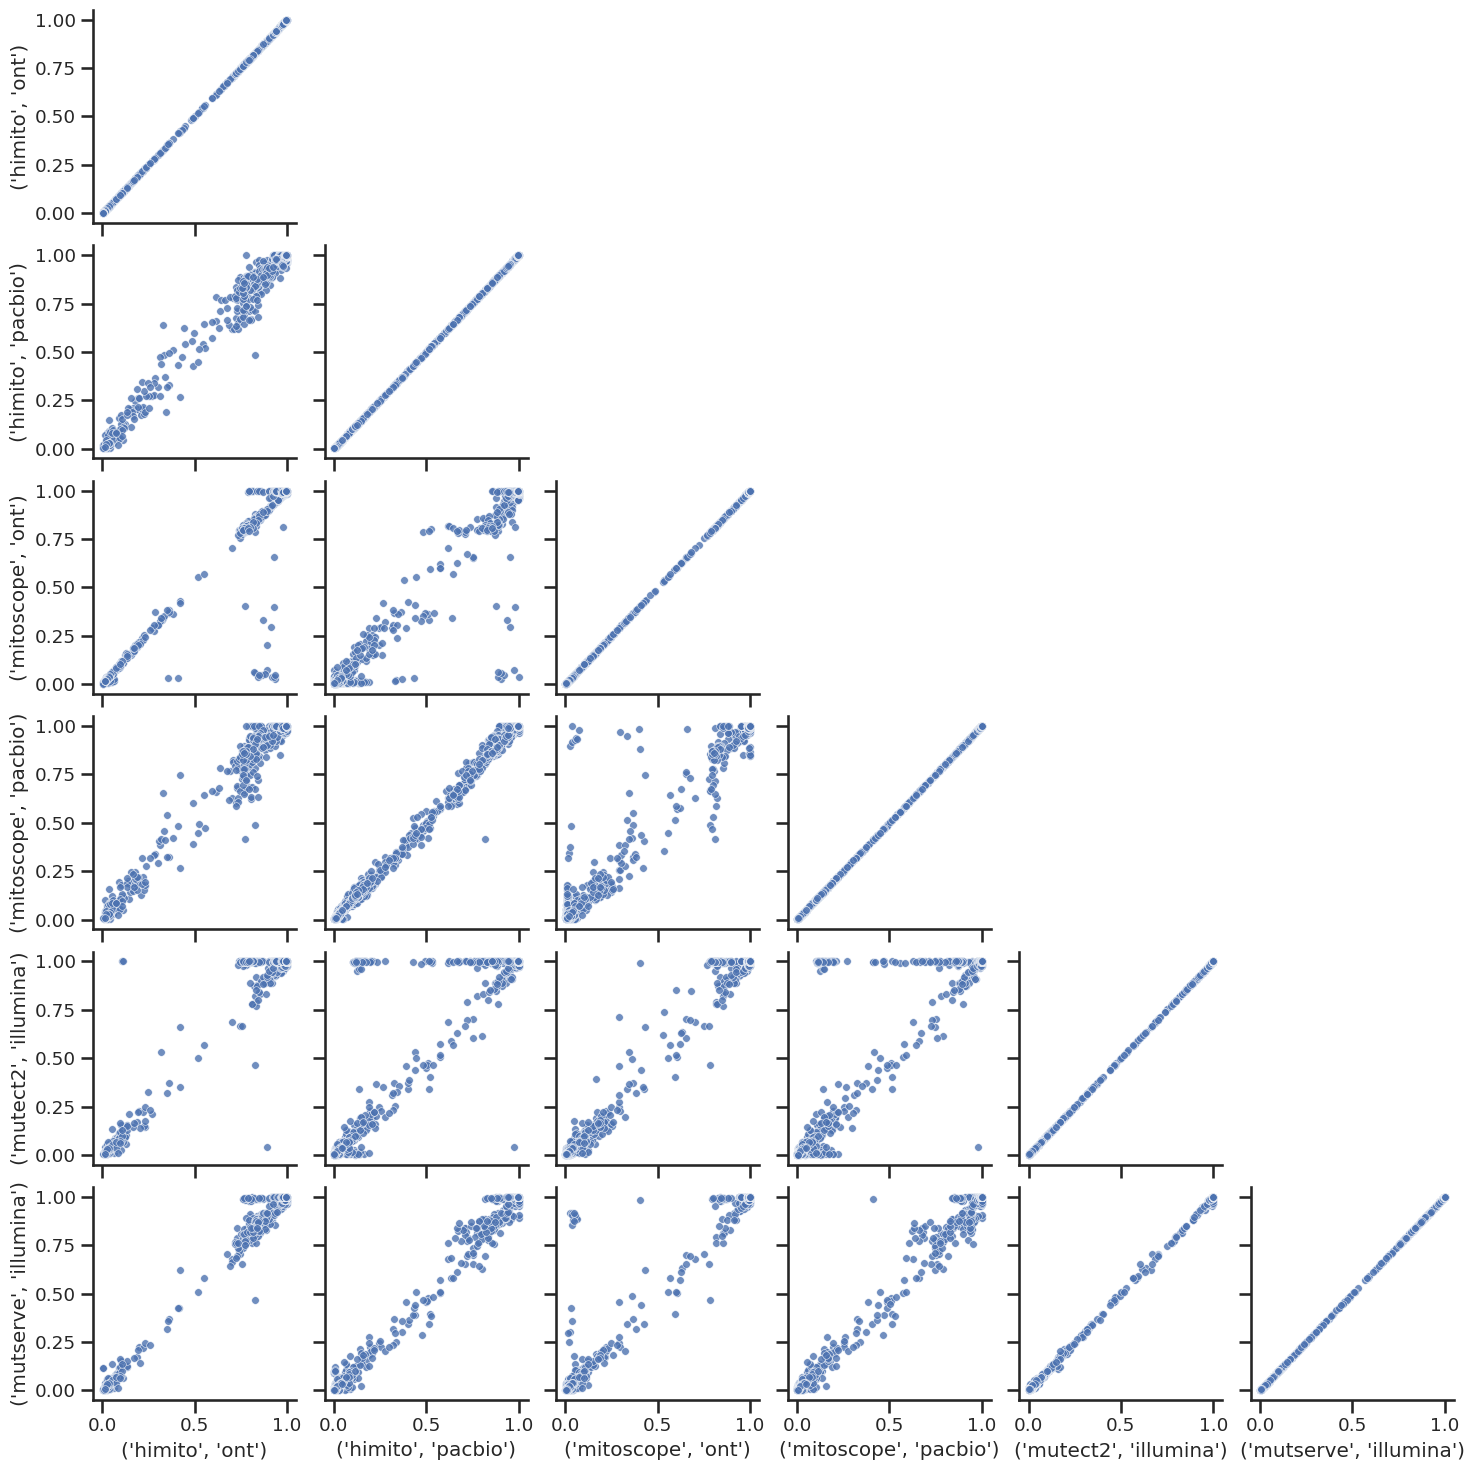

In [42]:
df_wide = comb_df.pivot_table(
    index=['ID', 'Donor_Tissue'],   # keep variant + donor paired
    columns=['Tool', 'Tech'],          # or ['Tech','Tool'] if needed
    values='AF'
).reset_index()

df_wide

corr = df_wide.drop(columns=['ID','Donor_Tissue']).corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=0.5, vmax=1)

plot_df = df_wide.drop(columns=['ID', 'Donor_Tissue'])

# Global limits across all variables
global_min = np.nanmin(plot_df.values)
global_max = np.nanmax(plot_df.values)

g = sns.pairplot(
    plot_df,
    corner=True,
    diag_kind=None,
    plot_kws={'alpha': 0.8, 's': 30},
)

pad = (global_max - global_min) * 0.05
# Set same limits for every subplot
for ax in g.axes.flatten():
    if ax is not None:
        ax.set_xlim(global_min - pad, global_max + pad)
        ax.set_ylim(global_min - pad, global_max + pad)

plt.show()

In [43]:
collapsed_df.columns

Index(['ID', 'Donor', 'Tissue', 'Donor_Tissue', 'n_tools', 'tools', 'n_techs',
       'techs', 'n_reps', 'mean_af', 'std_af', 'illumina', 'ont', 'pacbio',
       'avail_techs', 'n_avail_techs', 'avail_reps', 'n_avail_reps',
       'avail_tissues', 'n_avail_tissues', 'tissue_reps', 'tissue_rep_names',
       'CrossTech', 'CrossTool', 'CrossTissue', 'Category_Count', 'tier',
       'CHROM', 'POS', 'REF', 'ALT', 'indel', 'heteroplasmy_category',
       'variant_origin'],
      dtype='object')

In [44]:
## write to tsv file to use w bcftools annotate
for t in collapsed_df['Donor_Tissue'].unique():
    df = collapsed_df[collapsed_df['Donor_Tissue'] == t]
    df['GT'] = 1
    df = df[['CHROM', 'POS', 'REF', 'ALT', 'tier', 'techs', 'tools', 'tissue_rep_names', 'avail_techs', 'avail_tissues', 'illumina', 'ont', 'pacbio', 'heteroplasmy_category', 'variant_origin']]
    df['POS'] = df['POS'].astype(int)
    file_path=f"{INDIR}/output/merged/annotations/{t}.tsv"
    df.sort_values('POS').to_csv(file_path, sep='\t', index=False, header=False)

/tmp/ipykernel_2193816/4062534069.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['GT'] = 1
/tmp/ipykernel_2193816/4062534069.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['GT'] = 1
/tmp/ipykernel_2193816/4062534069.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-